In [1]:
pip install pyspark

In [2]:
import pyspark

In [3]:
from pyspark.sql import SparkSession

spark = SparkSession.builder.appName("PySpark Joins").getOrCreate()

In [4]:
from pyspark.sql.functions import *

# What is a Join?

A Join in PySpark is used to combine two DataFrames based on a common key (column).

# What is a Join?

**A join in PySpark is used to combine two DataFrames based on a common key (like student_id). Joins help you bring related data from different tables into one DataFrame.**


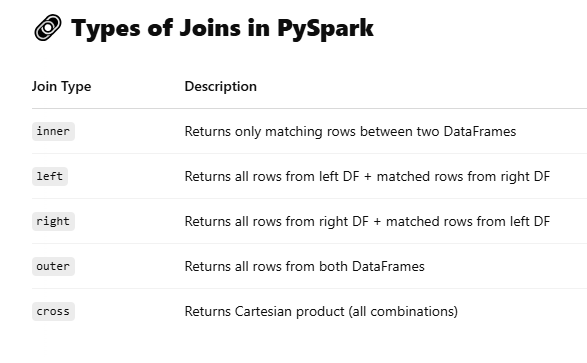

**Imagine you have:**

A DataFrame with student names and cities.

A DataFrame with student marks.

You want to see names and marks together. That's where joins come in!

Sample Data

In [5]:
df1_data = [
    (1, "Amit", "Delhi"),
    (2, "Priya", "Mumbai"),
    (3, "Rahul", "Kolkata"),
    (4, "Sneha", "Bangalore")
]
df1 = spark.createDataFrame(df1_data, ["student_id", "name", "city"])

df2_data = [
    (1, 85),
    (2, 90),
    (4, 95),
    (5, 88)
]
df2 = spark.createDataFrame(df2_data, ["student_id", "marks"])

df1.show()
df2.show()

+----------+-----+---------+
|student_id| name|     city|
+----------+-----+---------+
|         1| Amit|    Delhi|
|         2|Priya|   Mumbai|
|         3|Rahul|  Kolkata|
|         4|Sneha|Bangalore|
+----------+-----+---------+

+----------+-----+
|student_id|marks|
+----------+-----+
|         1|   85|
|         2|   90|
|         4|   95|
|         5|   88|
+----------+-----+



## ✅ 1. INNER JOIN

**Only matched student_ids from both DataFrames.**

In [ ]:
#syntax
df1.join(df2, on="column_name", how="inner").show()

df1.join(df2,  df1.id == df2.id, "inner").show()

# Both can be use
df1.join(df2,  df1.student_id == df2.s_id, "inner").show()

In [6]:
  # common rows
df1.join(df2, on="student_id", how="inner").show()

#Use Case: You only want students who have marks available.

+----------+-----+---------+-----+
|student_id| name|     city|marks|
+----------+-----+---------+-----+
|         1| Amit|    Delhi|   85|
|         2|Priya|   Mumbai|   90|
|         4|Sneha|Bangalore|   95|
+----------+-----+---------+-----+



In [7]:
df1.join(df2, df1.student_id == df2.student_id, "inner").show()

+----------+-----+---------+----------+-----+
|student_id| name|     city|student_id|marks|
+----------+-----+---------+----------+-----+
|         1| Amit|    Delhi|         1|   85|
|         2|Priya|   Mumbai|         2|   90|
|         4|Sneha|Bangalore|         4|   95|
+----------+-----+---------+----------+-----+



In [ ]:
df1.join(df2, df1.student_id == df2.student_id, "inner").show()

+----------+-----+---------+----------+-----+
|student_id| name|     city|student_id|marks|
+----------+-----+---------+----------+-----+
|         1| Amit|    Delhi|         1|   85|
|         2|Priya|   Mumbai|         2|   90|
|         4|Sneha|Bangalore|         4|   95|
+----------+-----+---------+----------+-----+



## ✅ 2. LEFT JOIN



In [9]:
df1.join(df2, on="student_id", how="left").show()   # common/matching rows + remaining from left DF

#Use Case: You want to show all students, even if some have not received marks yet.

+----------+-----+---------+-----+
|student_id| name|     city|marks|
+----------+-----+---------+-----+
|         1| Amit|    Delhi|   85|
|         2|Priya|   Mumbai|   90|
|         3|Rahul|  Kolkata| NULL|
|         4|Sneha|Bangalore|   95|
+----------+-----+---------+-----+



## 3️⃣ Right Join



In [10]:
df1.join(df2, on="student_id", how="right").show() # common rows + remaining rows from right DF

+----------+-----+---------+-----+
|student_id| name|     city|marks|
+----------+-----+---------+-----+
|         1| Amit|    Delhi|   85|
|         2|Priya|   Mumbai|   90|
|         5| NULL|     NULL|   88|
|         4|Sneha|Bangalore|   95|
+----------+-----+---------+-----+



## 4️⃣ FULL OUTER JOIN

**Returns all rows from both DataFrames. Missing matches are shown as null.**

In [ ]:
# matching rows + remaining from left DF + remaining from right DF

In [ ]:
df1.join(df2, on="student_id", how="outer").show()

#You want to see all students and all marks, even if they don’t match.

+----------+-----+---------+-----+
|student_id| name|     city|marks|
+----------+-----+---------+-----+
|         1| Amit|    Delhi|   85|
|         2|Priya|   Mumbai|   90|
|         3|Rahul|  Kolkata| NULL|
|         4|Sneha|Bangalore|   95|
|         5| NULL|     NULL|   88|
+----------+-----+---------+-----+



## 5️⃣ CROSS JOIN (CARTESIAN PRODUCT)

**Every row of df1 is joined with every row of df2.**

In [ ]:
df1.crossJoin(df2).show()

In [ ]:
df1.crossJoin(df2).show()


#Use with caution — useful when you want all combinations (e.g., seating plans, testing logic).

+----------+-----+---------+----------+-----+
|student_id| name|     city|student_id|marks|
+----------+-----+---------+----------+-----+
|         1| Amit|    Delhi|         1|   85|
|         1| Amit|    Delhi|         2|   90|
|         2|Priya|   Mumbai|         1|   85|
|         2|Priya|   Mumbai|         2|   90|
|         1| Amit|    Delhi|         4|   95|
|         1| Amit|    Delhi|         5|   88|
|         2|Priya|   Mumbai|         4|   95|
|         2|Priya|   Mumbai|         5|   88|
|         3|Rahul|  Kolkata|         1|   85|
|         3|Rahul|  Kolkata|         2|   90|
|         4|Sneha|Bangalore|         1|   85|
|         4|Sneha|Bangalore|         2|   90|
|         3|Rahul|  Kolkata|         4|   95|
|         3|Rahul|  Kolkata|         5|   88|
|         4|Sneha|Bangalore|         4|   95|
|         4|Sneha|Bangalore|         5|   88|
+----------+-----+---------+----------+-----+



# 6️⃣ Handling Duplicates Before Join

**Why?: If df1 or df2 has duplicate rows, you might get unexpected duplicated results in joins.**

In [ ]:
df1.distinct().join(df2, on="student_id", how="inner").show()


+----------+-----+---------+-----+
|student_id| name|     city|marks|
+----------+-----+---------+-----+
|         1| Amit|    Delhi|   85|
|         2|Priya|   Mumbai|   90|
|         4|Sneha|Bangalore|   95|
+----------+-----+---------+-----+



# 🔄 Join Using Different Column Names

In [ ]:
df1.join(df2, df1["student_id"] == df2["id"], "inner") # use when column name is different
df1.join(df2, df1.student_id == df2.id, "inner").show()

df1.join(df2, on="student_id", how="outer").show()

# Use Case: When the join columns have different names in each DataFrame.

In [ ]:
# ✅ Example When Column Names Are Different:

df1.join(df2, df1.student_id == df2.id, "inner").show()

#This wouldn't work with on="student_id" because the column names don’t match.

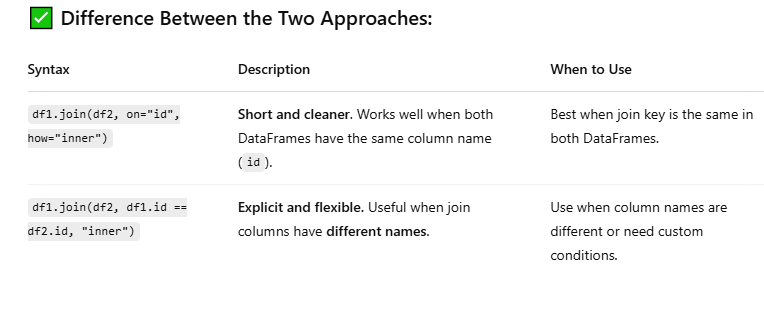

# Questions

In [ ]:
'''What are the different types of joins available in PySpark?
✅ Answer:

inner

left / left_outer

right / right_outer

full / full_outer

cross (Cartesian join)

left_semi

left_anti

'''

In [ ]:
'''What is the default join type in PySpark?
✅ Answer:

The default join type is inner join.

'''

In [ ]:
'''How do you perform a join in PySpark?
✅ Answer:
'''

In [ ]:
df1.join(df2, df1.id == df2.id, "inner")

In [ ]:
'''What will happen if both DataFrames have columns with the same name during join?
✅ Answer:

PySpark will add suffixes like _1 and _2 to avoid conflict.

You can also rename columns before join to avoid confusion.

'''

In [ ]:
''' Can you join on multiple columns in PySpark?
✅ Answer: Yes.'''

In [ ]:
df1.join(df2, (df1.id == df2.id) & (df1.city == df2.city), "inner")


In [ ]:
'''How do you handle nulls in join keys in PySpark?
✅ Answer:

Joins on null values do not match.

You can use fillna() or filter out nulls before join.'''